# Exploratory Data Analysis (EDA)

## 1. Objective and Scope

The objective of this notebook is to understand the dataset, investigate its main characteristics, and explore relationships between student characteristics and the target variable, `enade_score`.

The analysis focuses on understanding the data from a business and analytical perspective. Descriptive statistics, data visualizations, correlation and association measures, and statistical hypothesis tests are used to identify patterns, compare groups, and investigate potential data quality issues.

The exploratory analysis is conducted on the complete dataset before the train-test split. Its primary purpose is to understand the available data and generate insights, rather than to evaluate predictive performance.

## 2. Analysis Workflow

### 2.1. Dataset Overview
Inspect the dataset structure, variable types, descriptive statistics, and data quality.

### 2.2. Target Variable Analysis
Examine the distribution and descriptive characteristics of `enade_score`, including potentially unusual observations.

### 2.3. Exploratory Analysis of Relationships
Investigate relationships between the target variable and the available numerical and categorical variables using appropriate visualizations and summary statistics.

### 2.4. Correlation and Association Analysis
Explore relationships among variables using correlation coefficients and association measures appropriate to their data types.

### 2.5. Statistical Hypothesis Testing
Investigate whether observed differences in target values across selected categorical groups are supported by statistical evidence.

### 2.6. Data Quality Review and Cleaning
Investigate potential inconsistencies and determine whether any observations or values require correction or removal based on appropriate evidence.

### 2.7. Summary of Findings
Summarize the main findings, relevant patterns, and limitations identified during the exploratory analysis.

## 3. Interpretation of Findings

The results are interpreted in the context of the available variables and the characteristics of the dataset. Observed associations and group differences are not interpreted as evidence of causation.

The findings provide a descriptive understanding of the data and may inform subsequent analytical and modeling decisions. Predictive performance is evaluated separately in the regression notebook.

In [27]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import phik
import seaborn as sns
import scikit_posthocs as sp

from scipy.stats import mannwhitneyu, kruskal

from src.auxiliary import plot_blox_plot, pairplot, evaluate_features_statistics
from src.config import CLEAN_DATA_PATH, RAW_DATA_PATH

In [28]:
plt.style.use('default')

# 2. Analysis

## 2.1. Dataset Overview

### 2.1.1. Dataset Structure and Variable Types

The dataset is loaded and inspected to understand its structure, identify the available variables, and distinguish numerical from categorical features.

Descriptive statistics and frequency distributions are used to examine the dataset's main characteristics and identify potential issues that may require further investigation.

In [29]:

df_raw = pd.read_csv(RAW_DATA_PATH)

df_raw.head()

,sex,race/ethnicity,parental level of education,lunch,test preparation course,enade score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [30]:
df_raw.columns = df_raw.columns.str.replace(" ", "_")

df_raw.head()

,sex,race/ethnicity,parental_level_of_education,lunch,test_preparation_course,enade_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [31]:
categorical = [col for col in df_raw.select_dtypes(include='str')]

numerical = [col for col in df_raw.columns if col not in categorical]

print(f"""
Categorical Columns: {categorical}
Numerical Columns: {numerical}
""")


Categorical Columns: ['sex', 'race/ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course']
Numerical Columns: ['enade_score', 'reading_score', 'writing_score']



In [32]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   sex                          1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental_level_of_education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test_preparation_course      1000 non-null   str  
 5   enade_score                  1000 non-null   int64
 6   reading_score                1000 non-null   int64
 7   writing_score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 103.5 KB


In [33]:
df_raw.describe()

,enade_score,reading_score,writing_score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [34]:
df_raw.describe(exclude='number')

,sex,race/ethnicity,parental_level_of_education,lunch,test_preparation_course
count,1000,1000,1000,1000,1000
unique,2,5,6,2,2
top,female,group C,some college,standard,none
freq,518,319,226,645,642


In [35]:
for col in categorical:
    print(col)
    print(list(df_raw[col].unique()))
    print('')

sex
['female', 'male']

race/ethnicity
['group B', 'group C', 'group A', 'group D', 'group E']

parental_level_of_education
["bachelor's degree", 'some college', "master's degree", "associate's degree", 'high school', 'some high school']

lunch
['standard', 'free/reduced']

test_preparation_course
['none', 'completed']



In [36]:
for col in categorical:
    print(df_raw[col].value_counts())
    print('')

sex
female    518
male      482
Name: count, dtype: int64

race/ethnicity
group C    319
group D    262
group B    190
group E    140
group A     89
Name: count, dtype: int64

parental_level_of_education
some college          226
associate's degree    222
high school           196
some high school      179
bachelor's degree     118
master's degree        59
Name: count, dtype: int64

lunch
standard        645
free/reduced    355
Name: count, dtype: int64

test_preparation_course
none         642
completed    358
Name: count, dtype: int64



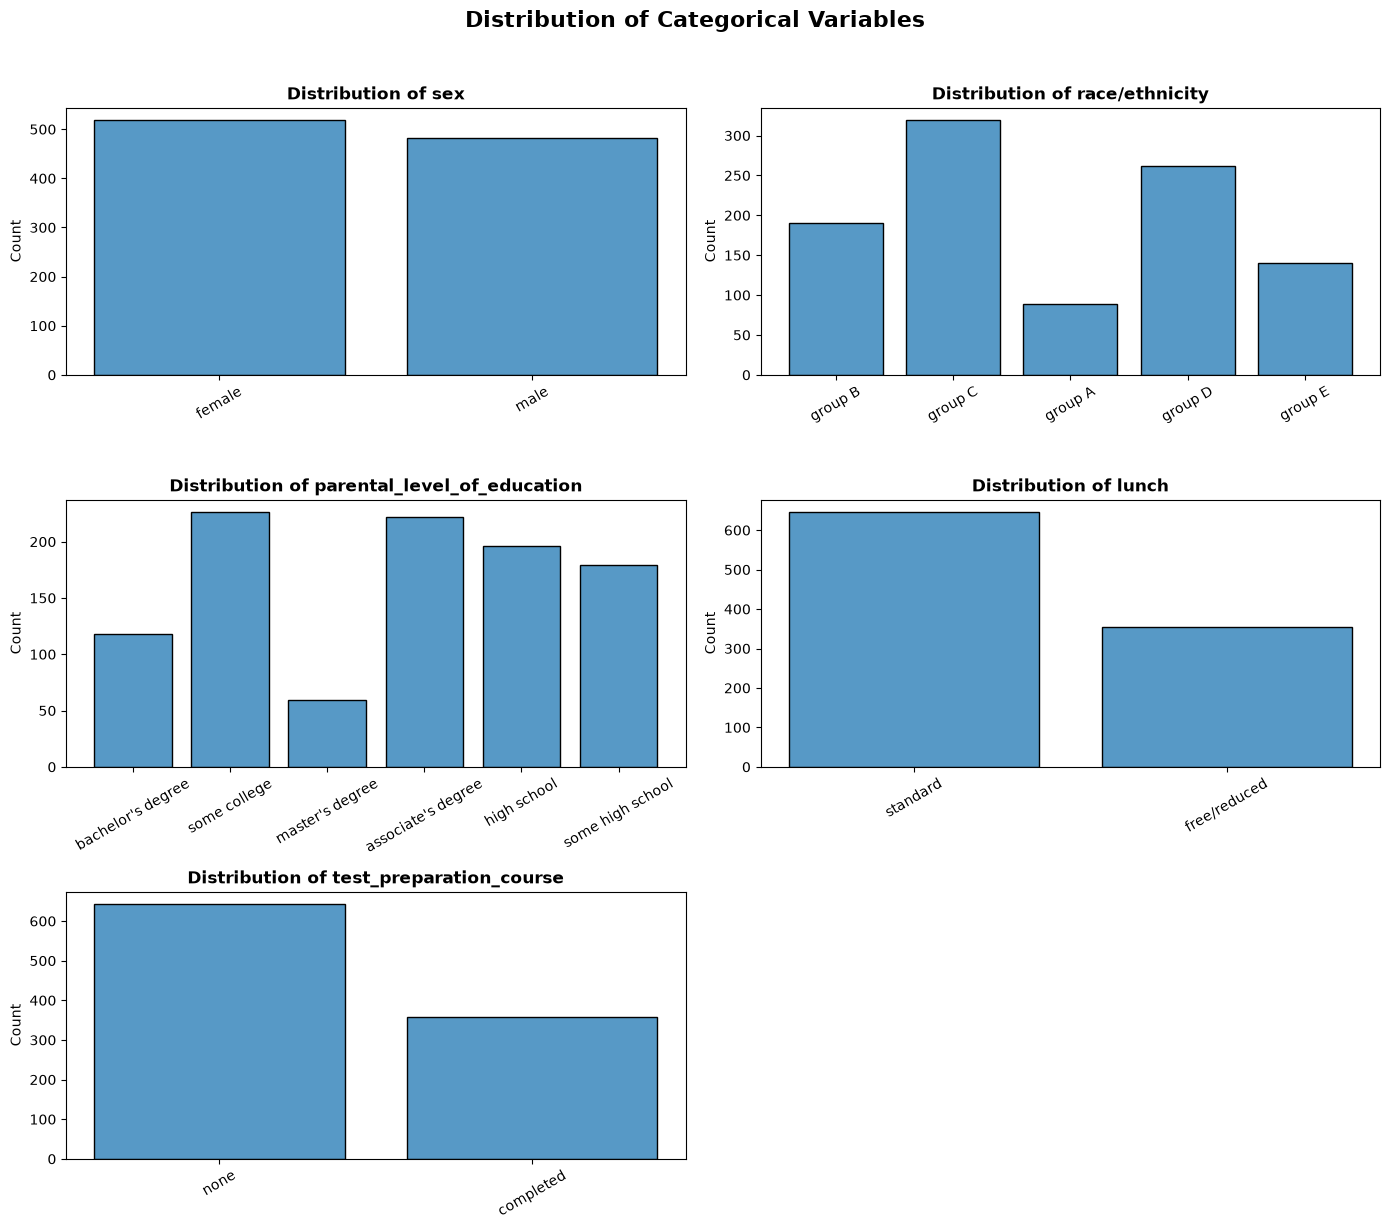

In [37]:
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(14, 12))
axes = axes.flatten()

for i, col in enumerate(categorical):
    sns.histplot(data=df_raw, x=col, ax=axes[i], shrink=0.8)
    axes[i].set_title(f"Distribution of {col}", fontsize=12, fontweight="bold")
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Count")
    axes[i].tick_params(axis="x", rotation=30)

# Remove unused axes (since we have 5 variables in a 3x2 grid)
if len(categorical) < len(axes):
    for j in range(len(categorical), len(axes)):
        fig.delaxes(axes[j])

plt.suptitle("Distribution of Categorical Variables", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## 2.2. Target Variable Analysis

This section examines the distribution and descriptive characteristics of `enade_score`. The analysis focuses on its range, central tendency, variability, and distribution shape, while identifying observations that may require further investigation.

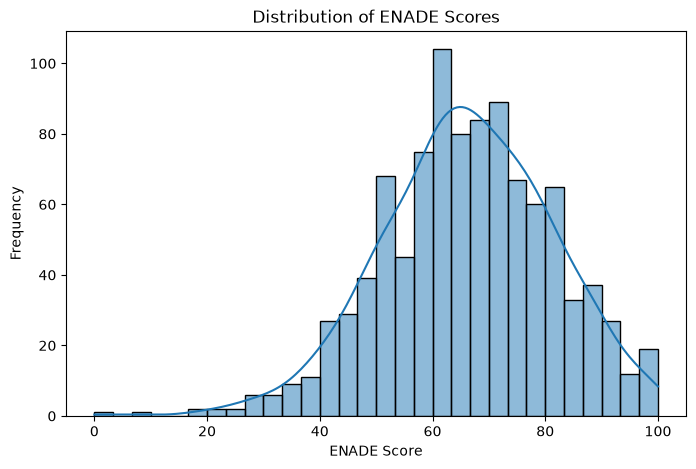

In [38]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_raw,
    x='enade_score',
    bins=30,
    kde=True
)

plt.title('Distribution of ENADE Scores')
plt.xlabel('ENADE Score')
plt.ylabel('Frequency')

plt.show()

In [39]:
df_raw['enade_score'].describe()

count    1000.00000
mean       66.08900
std        15.16308
min         0.00000
25%        57.00000
50%        66.00000
75%        77.00000
max       100.00000
Name: enade_score, dtype: float64

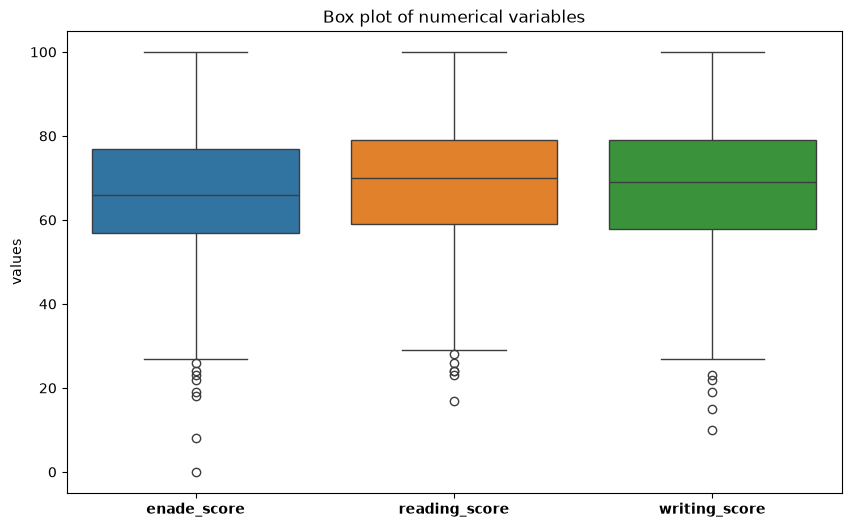

In [40]:
plt.figure(figsize=(10,6))

sns.boxplot(data=df_raw[numerical])

plt.xlabel('')
plt.ylabel('values')
plt.title('Box plot of numerical variables')

plt.xticks(fontweight='bold')

plt.show()

The boxplots show similar distributions and variability across the three numerical variables. Reading scores have the highest median, followed by writing scores and ENADE scores. All three variables present observations below the lower whiskers, indicating potential outliers according to the boxplot criterion. The ENADE score distribution includes a zero value, which warrants further investigation.

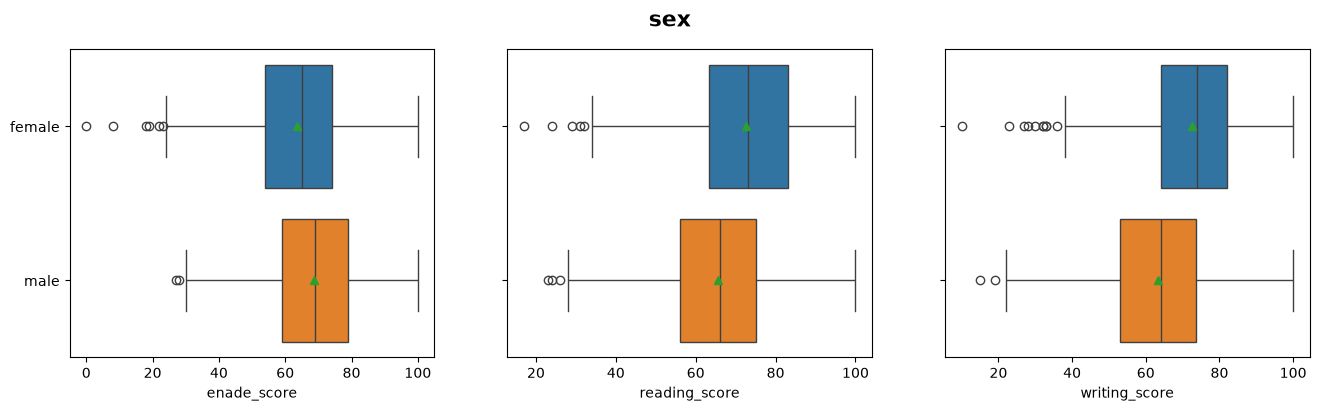

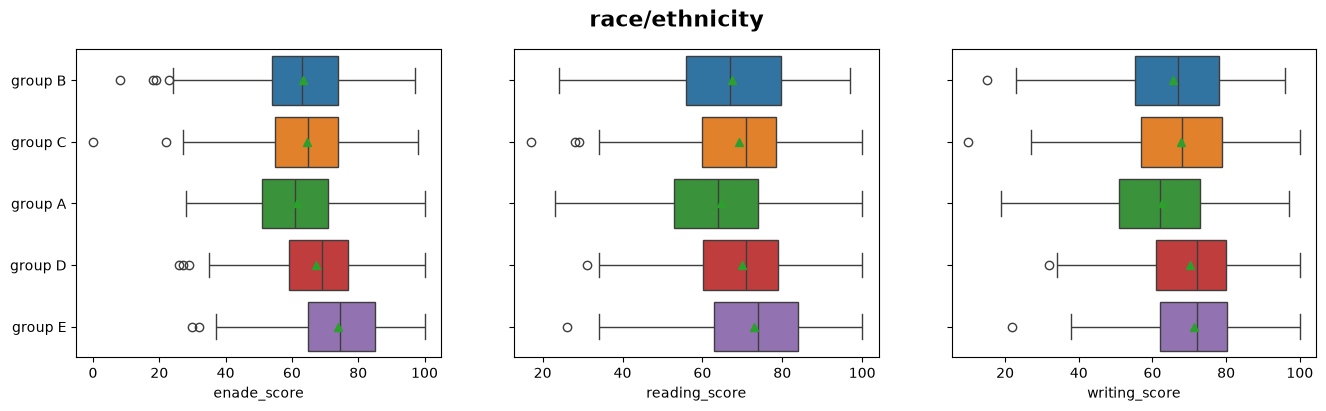

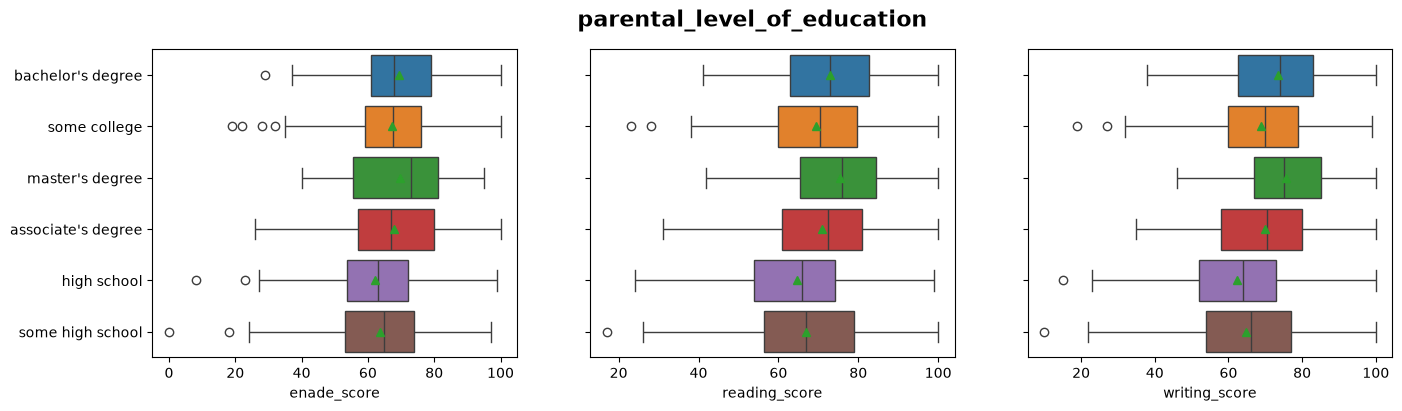

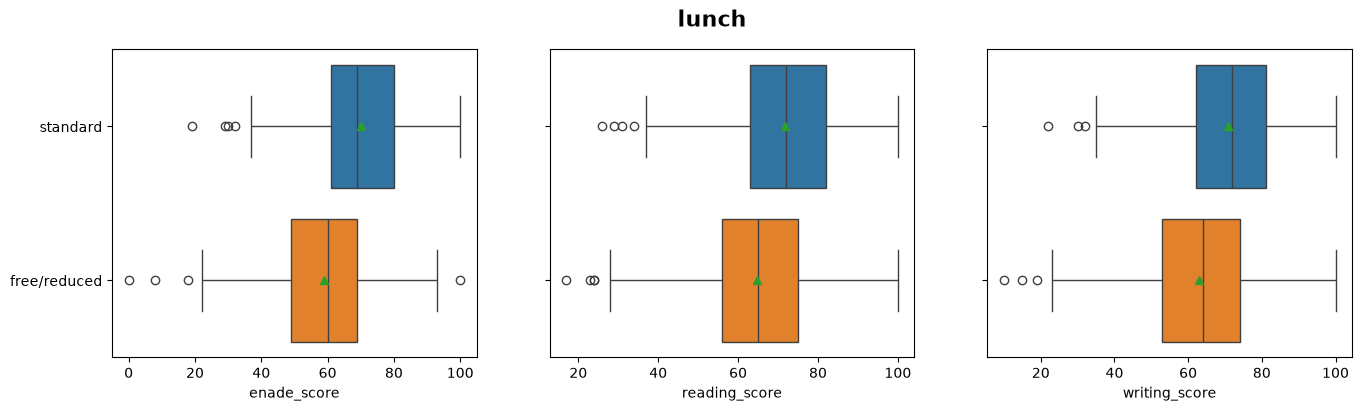

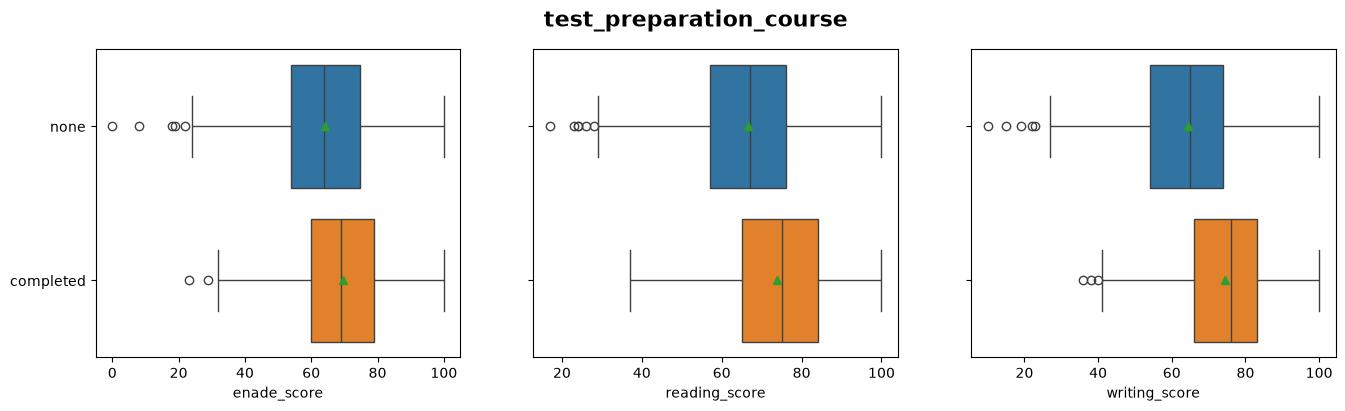

In [41]:
for cat in categorical:
    plot_blox_plot(df_raw, columns=numerical, target=cat)

**Interpretation**

The boxplots reveal differences in score distributions across several categorical variables.

- **Sex:** Female students have higher median reading and writing scores, while male students show a slightly higher median ENADE score. The distributions overlap, although the differences in reading and writing are visually more pronounced.

- **Race/ethnicity:** Group E generally exhibits higher median scores, particularly for reading and writing, while group A tends to have lower medians in these two assessments. However, the distributions overlap across groups.

- **Parental level of education:** Students whose parents hold bachelor's or master's degrees tend to have higher median scores in some assessments, whereas the high school category shows comparatively lower medians. Nevertheless, the distributions overlap substantially.

- **Lunch:** Students receiving standard lunch have higher median scores across all three assessments than those receiving free/reduced lunch. This pattern indicates an association between lunch category and academic performance.
Test preparation course: Students who completed the preparation course show higher median scores across all three assessments compared with those who did not complete it. The distributions still overlap, indicating that completion status alone does not fully distinguish student performance.

Overall, these plots suggest that academic scores vary across categorical groups, with particularly visible differences for lunch and test preparation course status. These are descriptive observations; the statistical tests presented later in the notebook provide additional evidence for evaluating group differences.

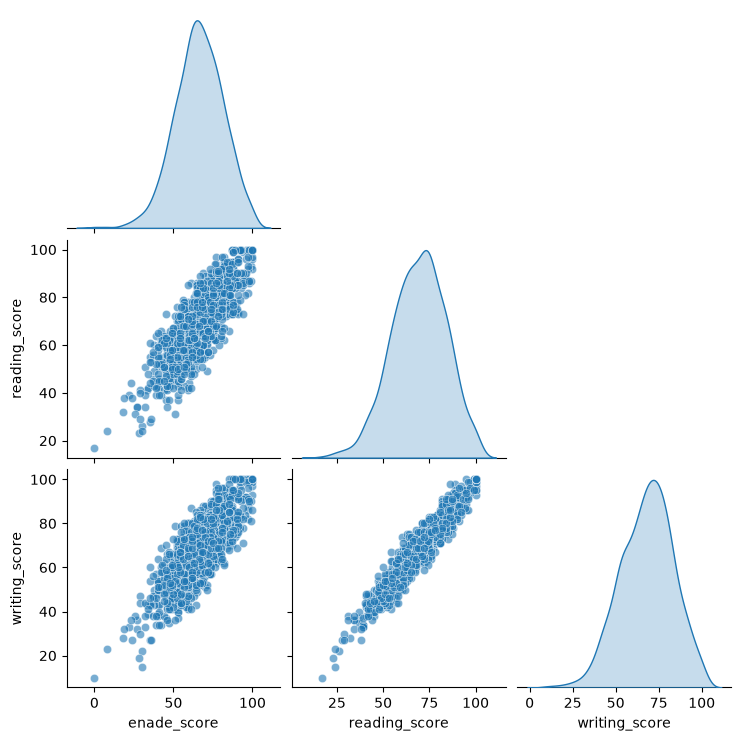

In [42]:
pairplot(df_raw, numerical)

### Interpretation

The pairplot reveals positive relationships among all three numerical variables.

- **`reading_score` and `writing_score`:** These variables exhibit a strong positive relationship. Students with higher reading scores generally also have higher writing scores, and the points follow a relatively narrow, approximately linear pattern.
- **`enade_score` and `reading_score`:** A positive relationship is also visible, although the points are more dispersed than in the reading-writing comparison.
- **`enade_score` and `writing_score`:** These variables show a strong positive relationship, with higher writing scores generally associated with higher ENADE scores.

The diagonal density plots show the distributions of the individual variables. The scores are concentrated around their central ranges, with fewer observations toward the lower and upper ends of the scales.

Overall, the plots suggest that the three scores are positively associated, particularly reading and writing. These visual patterns are descriptive and do not establish causation.

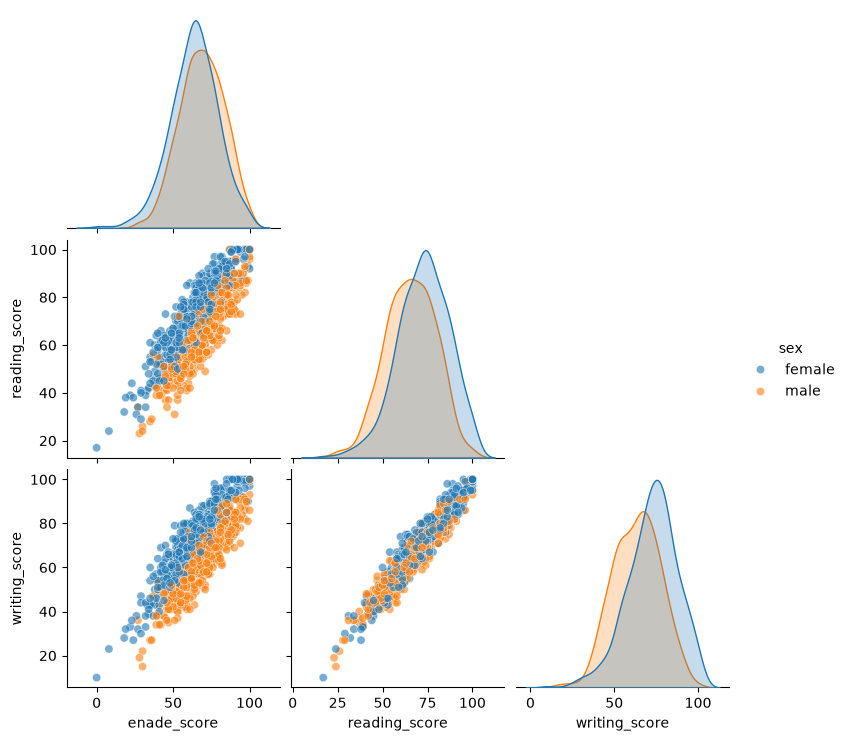

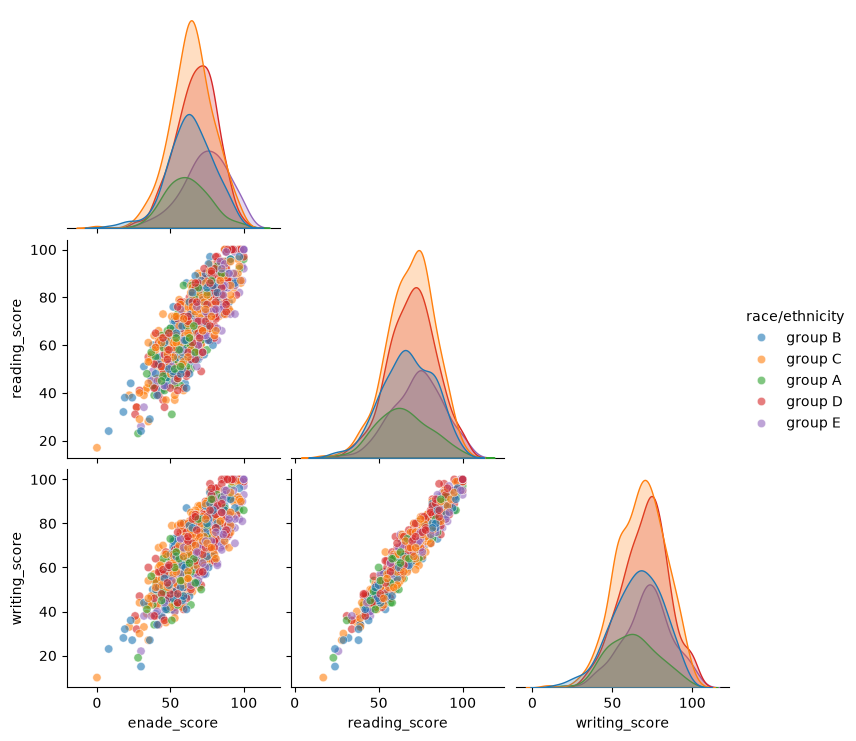

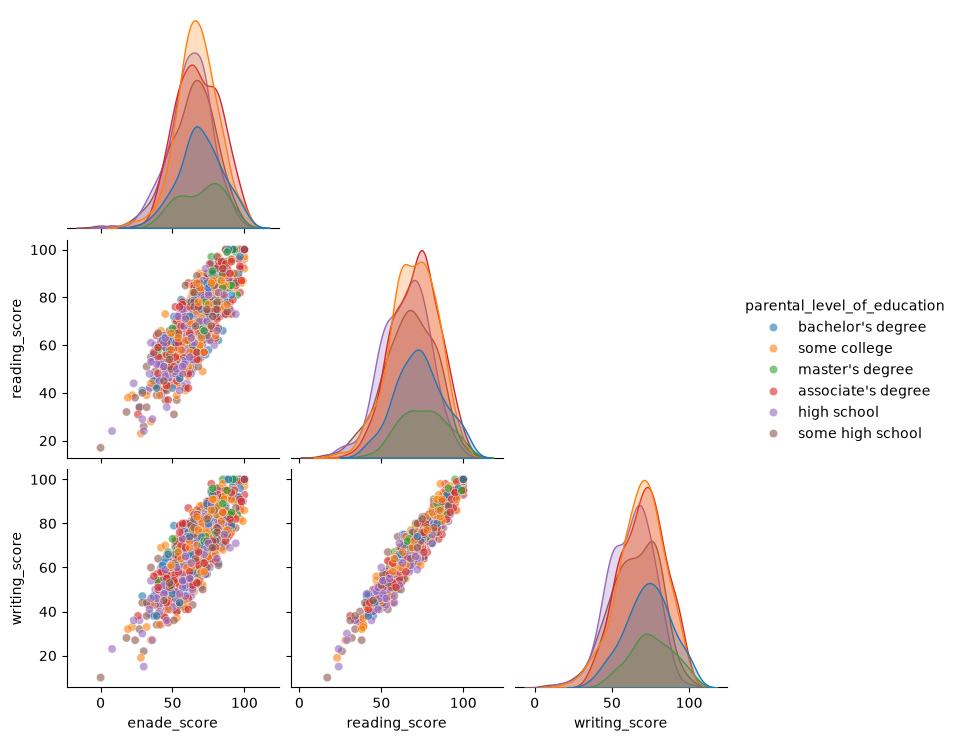

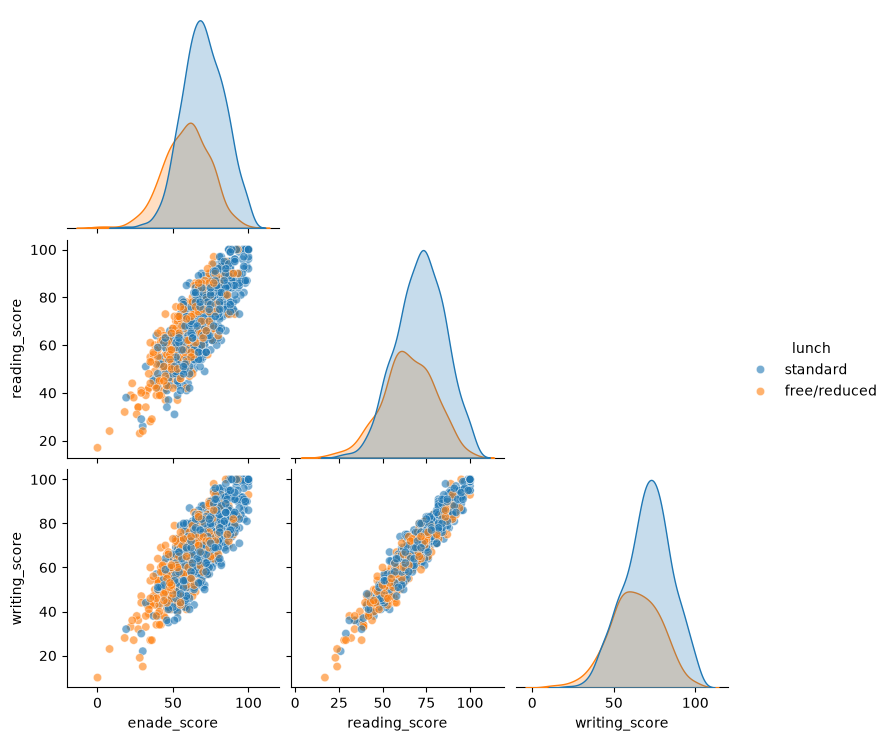

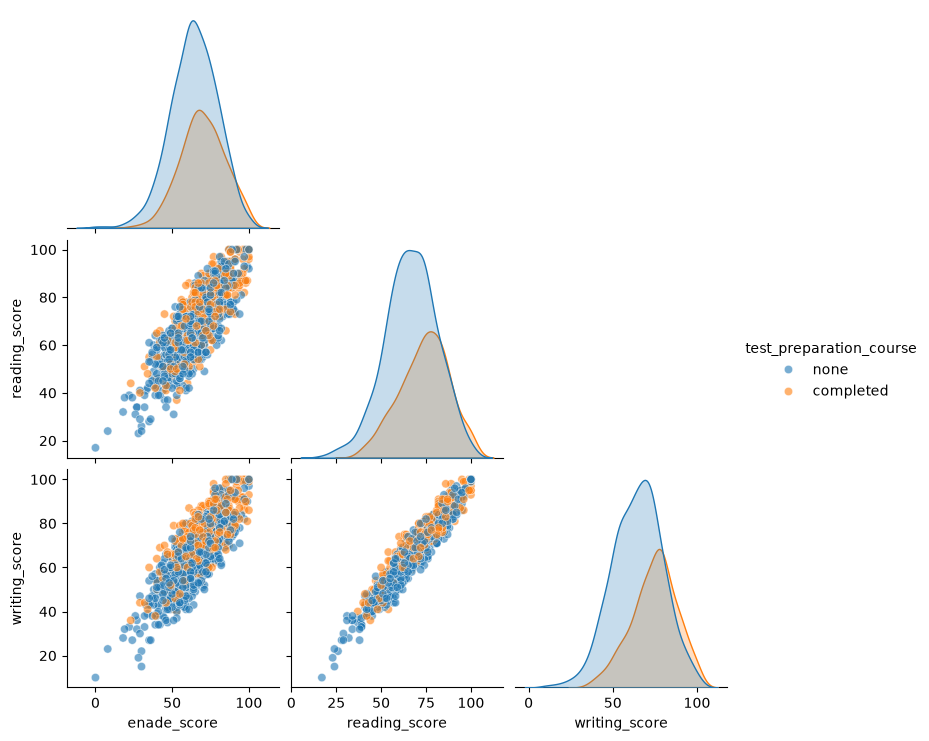

In [43]:
for cat in categorical:
    pairplot(df_raw, pairplot_columns=numerical, hue_column=cat)

### Interpretation

The pairplots colored by categorical variables provide additional insight into how score distributions and relationships vary across student groups.

- **Sex:** Female students tend to have higher reading and writing scores, while the ENADE score distributions overlap considerably between the two groups. The positive relationships among the three scores remain visible for both groups.
- **Race/ethnicity:** The groups show substantial overlap in their score distributions. Some differences in the concentration of observations are visible, but the score relationships follow broadly similar positive patterns across groups.
- **Parental level of education:** The score distributions overlap across parental education categories. Although some groups appear to have different score concentrations, the pairplots do not show a clear separation between categories.
- **Lunch:** Students in the standard lunch category tend to have higher scores, particularly in reading and writing. However, the two groups overlap, and the positive relationships among scores remain evident in both.
- **Test preparation course:** Students who completed the preparation course tend to be more concentrated in higher score ranges, particularly for reading and writing. Nevertheless, the distributions overlap, and the relationship between reading and writing remains strong in both groups.

Overall, the categorical pairplots show that differences in score distributions coexist with substantial overlap between groups. The positive relationships among the numerical variables remain visible across the categories, suggesting that these relationships are not restricted to a single group. These visual comparisons are descriptive; the statistical analyses that follow provide a complementary way to investigate group differences.

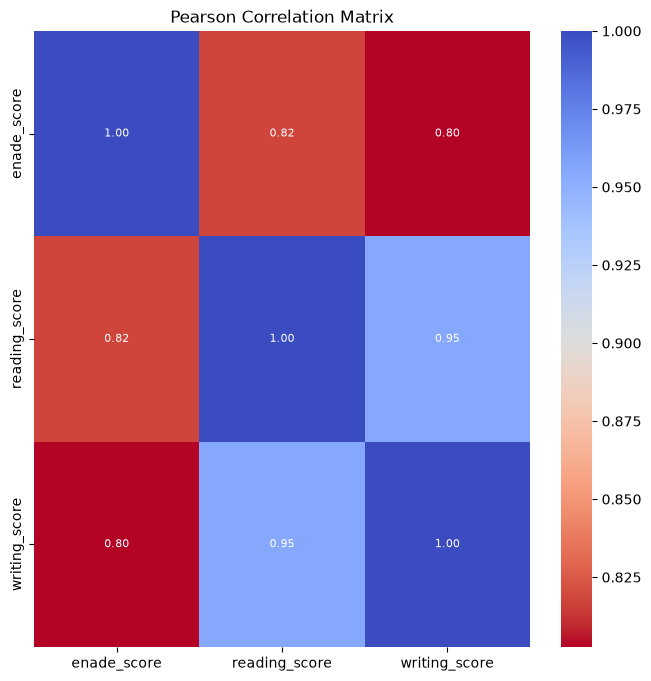

In [44]:
corr = df_raw.select_dtypes("number").corr()

# matriz = np.triu(corr)

fig, ax = plt.subplots(figsize=(8, 8))

sns.heatmap(
    corr,
    # mask=matriz,
    cmap="coolwarm_r",
    annot=True,
    fmt=".2f",
    ax=ax,
    annot_kws={"fontsize": 8}
)

plt.title("Pearson Correlation Matrix")

plt.show()

### Pearson Correlation Matrix

The Pearson correlation matrix shows positive linear relationships among all three numerical variables. The strongest correlation is observed between `reading_score` and `writing_score` (r = 0.95). The correlations between `enade_score` and `reading_score` (r = 0.82), and between `enade_score` and `writing_score` (r = 0.80), are also strong.

These results indicate that higher reading and writing scores tend to be associated with higher ENADE scores. The strong correlation between reading and writing suggests substantial overlap in their linear relationships, which may be relevant when evaluating their individual contributions to the regression model.

interval columns not set, guessing: ['enade_score', 'reading_score', 'writing_score']


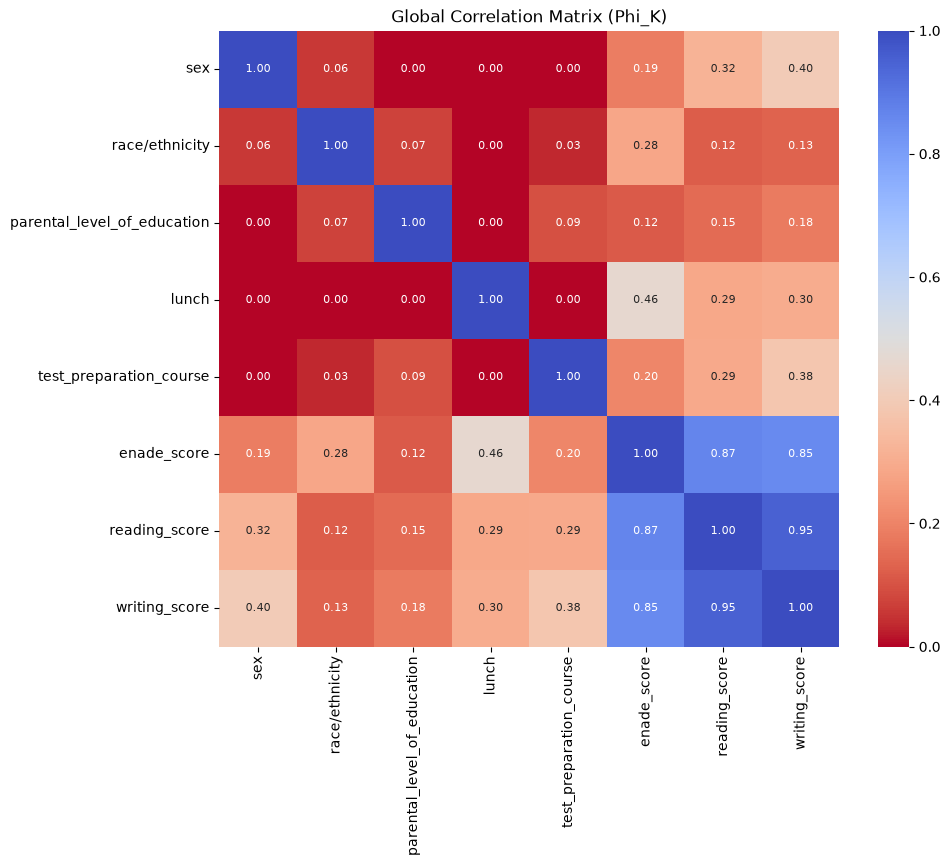

In [45]:
corr_phik = df_raw.phik_matrix()

fig, ax = plt.subplots(figsize=(10, 8))

sns.heatmap(
    corr_phik, 
    cmap="coolwarm_r", 
    annot=True, 
    fmt=".2f", 
    ax=ax,
    vmin=0,       
    vmax=1,
    annot_kws={"fontsize": 8}
)

plt.title("Global Correlation Matrix (Phi_K)")
plt.show()

### Global Association Matrix (Phi_K)

The Phi_K matrix captures associations among both numerical and categorical variables. The strongest associations are observed among the three numerical scores: `enade_score` with `reading_score` (0.87), `enade_score` with `writing_score` (0.85), and `reading_score` with `writing_score` (0.95). These results are consistent with the Pearson correlation analysis, although the coefficients are not directly equivalent because the two measures differ.

Among the categorical variables and the scores, the strongest association is observed between `lunch` and `enade_score` (0.46). Other notable associations include `sex` with `writing_score` (0.40), `test_preparation_course` with `writing_score` (0.38), and `sex` with `reading_score` (0.32).

Associations between `parental_level_of_education` and the scores are comparatively weaker, with coefficients of 0.12 for `enade_score`, 0.15 for `reading_score`, and 0.18 for `writing_score`. Associations among the categorical variables are also generally low.

Overall, the matrix provides a complementary view of the relationships in the dataset, including associations involving categorical variables. These coefficients describe association strength but do not establish causality or, by themselves, demonstrate statistical significance.

### 2.5. Statistical Hypothesis Testing

In [46]:
features = ['lunch', 'test_preparation_course', 'parental_level_of_education']

evaluate_features_statistics(df=df_raw, group_cols=features, target_col='enade_score')

 FEATURE: LUNCH vs ENADE_SCORE
Number of groups: 2

--- Normality Check (Shapiro-Wilk) ---
Overall Normal: False
  > Group 'free/reduced': stat = 0.9925, p-value = 0.0716 -> Normal: True
  > Group 'standard': stat = 0.9944, p-value = 0.0181 -> Normal: False

--- Variance Check (Levene) ---
Equal Variance: True
Statistic = 3.1938, p-value = 0.0742

--- Suggested Statistical Test ---
-> Mann-Whitney U Test (mannwhitneyu)


 FEATURE: TEST_PREPARATION_COURSE vs ENADE_SCORE
Number of groups: 2

--- Normality Check (Shapiro-Wilk) ---
Overall Normal: False
  > Group 'completed': stat = 0.9937, p-value = 0.1393 -> Normal: True
  > Group 'none': stat = 0.9921, p-value = 0.0018 -> Normal: False

--- Variance Check (Levene) ---
Equal Variance: True
Statistic = 0.5330, p-value = 0.4655

--- Suggested Statistical Test ---
-> Mann-Whitney U Test (mannwhitneyu)


 FEATURE: PARENTAL_LEVEL_OF_EDUCATION vs ENADE_SCORE
Number of groups: 6

--- Normality Check (Shapiro-Wilk) ---
Overall Normal: False
  > 

#### Test Selection

Before conducting the hypothesis tests, the distributions of `enade_score` were assessed within each categorical group using the Shapiro–Wilk test. Homogeneity of variances was evaluated using Levene's test.

The normality checks indicated statistically significant deviations from normality in at least one group for each categorical variable. Levene's tests did not detect statistically significant differences in group variances at the 0.05 significance level.

Based on these diagnostics and the group structures, non-parametric tests were selected: the Mann–Whitney U test for `lunch` and `test_preparation_course`, each comprising two independent groups, and the Kruskal–Wallis H test for `parental_level_of_education`, which comprises six groups.

The significance level was set at $\alpha = 0.05$.

In [47]:
# ==========================================
# 1. Mann-Whitney U Test: Lunch
# ==========================================
group_standard = df_raw[df_raw['lunch'] == 'standard']['enade_score'].dropna()
group_free = df_raw[df_raw['lunch'] == 'free/reduced']['enade_score'].dropna()

stat_lunch, p_lunch = mannwhitneyu(group_standard, group_free, alternative='two-sided')
print(f"--- LUNCH ---")
print(f"Mann-Whitney U: p-value = {p_lunch:.4e}")
print(f"Significant difference? {'Yes' if p_lunch < 0.05 else 'No'}\n")

# ==========================================
# 2. Mann-Whitney U Test: Test Preparation Course
# ==========================================
group_completed = df_raw[df_raw['test_preparation_course'] == 'completed']['enade_score'].dropna()
group_none = df_raw[df_raw['test_preparation_course'] == 'none']['enade_score'].dropna()

stat_prep, p_prep = mannwhitneyu(group_completed, group_none, alternative='two-sided')
print(f"--- TEST PREPARATION COURSE ---")
print(f"Mann-Whitney U: p-value = {p_prep:.4e}")
print(f"Significant difference? {'Yes' if p_prep < 0.05 else 'No'}\n")

# ==========================================
# 3. Kruskal-Wallis H Test: Parental Level of Education
# ==========================================
# Extract arrays for each educational level
groups_parental = [group['enade_score'].dropna().values for _, group in df_raw.groupby('parental_level_of_education')]

stat_kruskal, p_kruskal = kruskal(*groups_parental)
print(f"--- PARENTAL LEVEL OF EDUCATION ---")
print(f"Kruskal-Wallis H: p-value = {p_kruskal:.4e}")
print(f"Significant difference? {'Yes' if p_kruskal < 0.05 else 'No'}")

--- LUNCH ---
Mann-Whitney U: p-value = 1.5220e-26
Significant difference? Yes

--- TEST PREPARATION COURSE ---
Mann-Whitney U: p-value = 8.0152e-08
Significant difference? Yes

--- PARENTAL LEVEL OF EDUCATION ---
Kruskal-Wallis H: p-value = 7.1162e-05
Significant difference? Yes


#### Interpretation of Hypothesis Tests

At a significance level of 0.05, all three hypothesis tests yielded statistically significant results.

The Mann–Whitney U test identified a statistically significant difference in `enade_score` distributions between the two `lunch` groups (p = 1.5220 × 10⁻²⁶). This result is consistent with the boxplots, which showed a higher median ENADE score for students in the `standard` lunch group.

A statistically significant difference was also observed between students who completed the test preparation course and those who did not (Mann–Whitney U test, p = 8.0152 × 10⁻⁸). The boxplots showed a higher median ENADE score for the `completed` group.

The Kruskal–Wallis test also indicated a statistically significant difference in ENADE score distributions across parental education levels (p = 7.1162 × 10⁻⁵). However, this result establishes only that at least one group differs from another; it does not identify which specific pairs of groups differ.

Overall, these results provide statistical evidence supporting the group differences observed during exploratory analysis. However, statistical significance alone does not quantify the magnitude or practical importance of these differences, nor does it establish causal relationships.

In [48]:
# ==========================================
# Descriptive Medians for Binary Groups
# ==========================================
print("--- LUNCH MEDIANS ---")
print(df_raw.groupby('lunch')['enade_score'].median(), "\n")

print("--- TEST PREPARATION MEDIANS ---")
print(df_raw.groupby('test_preparation_course')['enade_score'].median(), "\n")

--- LUNCH MEDIANS ---
lunch
free/reduced    60.0
standard        69.0
Name: enade_score, dtype: float64 

--- TEST PREPARATION MEDIANS ---
test_preparation_course
completed    69.0
none         64.0
Name: enade_score, dtype: float64 



--- PARENTAL EDUCATION MEDIANS ---
parental_level_of_education
master's degree       73.0
bachelor's degree     68.0
some college          67.5
associate's degree    67.0
some high school      65.0
high school           63.0
Name: enade_score, dtype: float64 



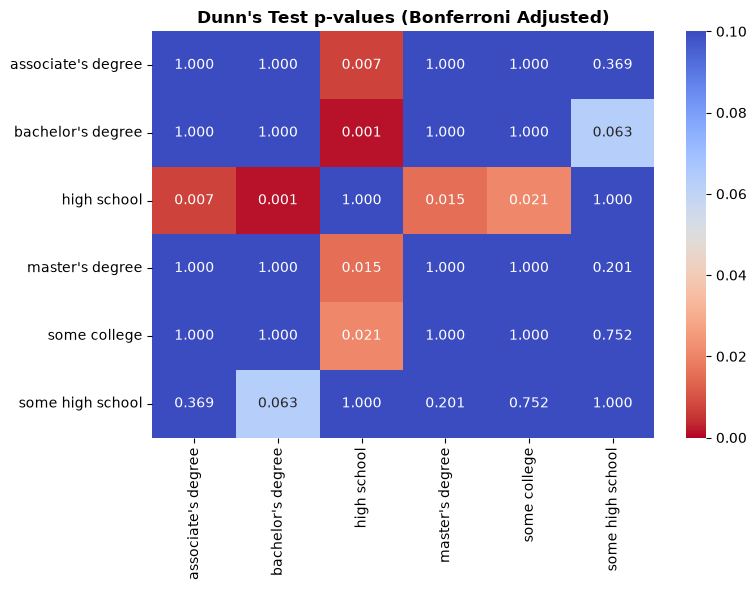

In [ ]:
# ==========================================
# Post-Hoc Dunn's Test: Parental Level of Education
# ==========================================
# 1. Check the median of each group to establish the ranking
print("--- PARENTAL EDUCATION MEDIANS ---")
medians = df_raw.groupby('parental_level_of_education')['enade_score'].median().sort_values(ascending=False)
print(medians, "\n")

# 2. Apply Dunn's Test with Bonferroni correction
dunn_matrix = sp.posthoc_dunn(
    df_raw, 
    val_col='enade_score', 
    group_col='parental_level_of_education', 
    p_adjust='bonferroni'
)

# 3. Plot the p-value matrix as a heatmap for easy reading
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    dunn_matrix, 
    annot=True, 
    cmap='coolwarm_r',
    fmt=".3f", 
    vmin=0, 
    vmax=0.1, 
    ax=ax
)
ax.set_title("Dunn's Test p-values (Bonferroni Adjusted)", fontweight="bold")
plt.tight_layout()
plt.show()

#### Interpretation of Dunn's Post-Hoc Test

The heatmap presents the pairwise p-values adjusted using the Bonferroni correction. At a significance level of 0.05, four comparisons involving the `high school` group were statistically significant: `associate's degree` (p = 0.007), `bachelor's degree` (p = 0.001), `master's degree` (p = 0.015), and `some college` (p = 0.021).

The `high school` group had a median ENADE score of 63.0, compared with medians of 67.0, 68.0, 73.0, and 67.5 for these four groups, respectively. These results indicate statistically significant differences in the score distributions for the identified comparisons.

No statistically significant differences were detected in the remaining pairwise comparisons after Bonferroni adjustment. In particular, the comparison between `high school` and `some high school` yielded an adjusted p-value of 1.000. This result does not establish that the groups are equivalent; it indicates that the test did not detect a statistically significant difference between them.

Overall, the post-hoc analysis provides more specific evidence about the group differences identified by the Kruskal–Wallis test. These findings describe associations between parental education categories and ENADE scores. They do not establish causality or, on their own, determine whether `parental_level_of_education` improves predictive performance in the regression model.

### 2.6. Data Quality Review and Cleaning

This section examines potential data quality issues identified during exploratory analysis and documents the decisions made before preparing the dataset for regression modeling.

In [50]:
df = df_raw.copy()

df.head()

,sex,race/ethnicity,parental_level_of_education,lunch,test_preparation_course,enade_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [51]:
df.describe()

,enade_score,reading_score,writing_score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [52]:
df[df['enade_score'] == 0]

,sex,race/ethnicity,parental_level_of_education,lunch,test_preparation_course,enade_score,reading_score,writing_score
59,female,group C,some high school,free/reduced,none,0,17,10


The record at index 59 has an `enade_score` of 0, while its `reading_score` and `writing_score` are 17 and 10, respectively. This combination makes the observation worth investigating because the target score differs substantially from the other two recorded scores.

However, the available dataset does not establish why the ENADE score is zero. Possible explanations cannot be confirmed from these variables alone. Therefore, the record should not be classified as erroneous solely on the basis of this discrepancy.

For this analysis, the record is excluded from the working dataset as a documented data-cleaning decision. This exclusion is a methodological choice rather than a confirmed correction of an erroneous value. Its potential influence on the analysis should be considered when interpreting subsequent results.

In [ ]:
df = df.drop(index=59)

In [27]:
df.describe()

,enade_score,reading_score,writing_score
count,999.000000,999.000000,999.000000
mean,66.155155,69.221221,68.112112
std,15.025594,14.513766,15.091685
min,8.000000,23.000000,15.000000
25%,57.000000,59.000000,58.000000
50%,66.000000,70.000000,69.000000
75%,77.000000,79.000000,79.000000
max,100.000000,100.000000,100.000000


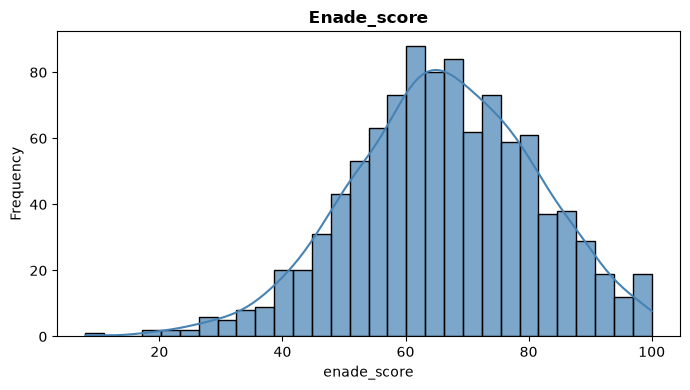

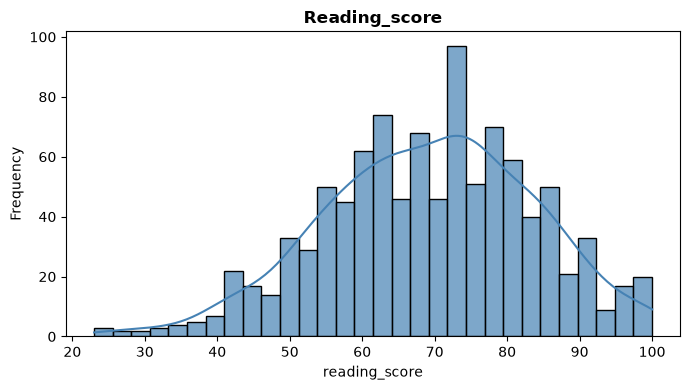

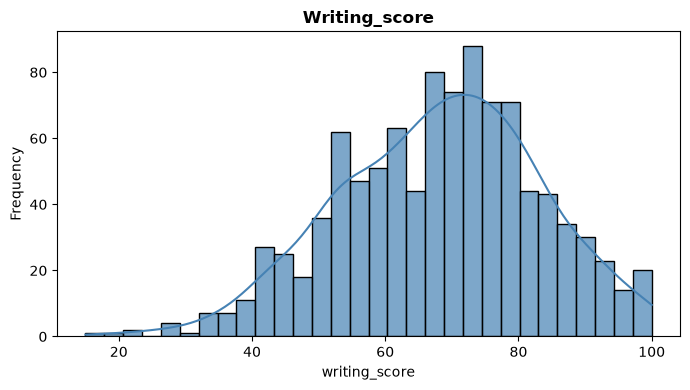

In [28]:
for col in numerical:
    plt.figure(figsize=(7, 4))
    
    # Using Seaborn to handle the histogram and KDE scaling automatically
    sns.histplot(data=df, x=col, bins=30, color="steelblue", alpha=0.7, kde=True)
    
    plt.title(col.capitalize(), fontweight='bold')
    # plt.xlabel(col.capitalize())
    plt.ylabel("Frequency")
    
    plt.tight_layout()
    plt.show()

### Distribution of Numerical Variables

The histograms and kernel density estimates (KDEs) show the distributions of `enade_score`, `reading_score`, and `writing_score` after the data-cleaning step.

The `enade_score` distribution is unimodal, with most observations concentrated between approximately 55 and 80 points and a peak around 60–65. The `reading_score` distribution is also broadly unimodal, with a higher concentration of observations between approximately 55 and 85 points. Similarly, `writing_score` is concentrated mainly between approximately 50 and 85 points, with a peak around 70–75.

Although the three distributions share a broadly unimodal shape, they exhibit local irregularities and some asymmetry, particularly in their lower-score tails. These visual patterns provide a descriptive overview of the variables but are not sufficient to establish whether they follow normal distributions.

The distributions are examined here to understand the data and identify potential features that may warrant further investigation. The suitability of the linear regression model will be assessed through the relationships between predictors and the target, as well as the model's residual behavior, rather than by requiring the target variable itself to be normally distributed.

### Preprocessing and Modeling Plan

To preserve data integrity and prevent data leakage, the preprocessing transformations will be applied within the modeling pipeline, **after the data have been split into training and test sets**. This ensures that transformations requiring parameter estimation are fitted exclusively on the training data.

The preprocessing strategy will use a `ColumnTransformer` with the following configuration:

- **Numerical predictors (`reading_score`, `writing_score`):** Apply `StandardScaler` to standardize the predictors by subtracting the training-set mean and dividing by the training-set standard deviation. This is particularly relevant for regularized regression models, such as Ridge, Lasso, because their penalties are sensitive to predictor scales.

- **Categorical predictors (`sex`, `race/ethnicity`, `parental_level_of_education`, `lunch`, `test_preparation_course`):** Apply `OneHotEncoder(drop='first', sparse_output=False)` to convert categorical values into binary indicator variables. Dropping one category per feature avoids perfect linear dependence among the encoded categories when the regression model includes an intercept.

- **Target variable (`enade_score`):** Retain the target on its original scale, without applying a mathematical transformation. This preserves the direct interpretation of predictions and regression errors in score points. The decision does not rely on an assumption that the target variable follows a normal distribution.

### Data Type Standardization and Export

Before exporting the cleaned dataset, numerical variables are stored as `int16`, which is sufficient for the observed examination score range. Categorical variables are explicitly converted to strings to ensure consistent data types.

The resulting dataset is saved in Parquet format for use in the modeling stage. This step preserves the cleaned observations and their data types while keeping the exploratory analysis separate from model-specific preprocessing.

The numerical scaling and categorical encoding required by the predictive models are performed later within the modeling workflow, after the training and test sets have been separated.

In [29]:
df[numerical] = df[numerical].astype('int16')

for col in categorical:
    df[col] = df[col].astype(str)

print(df.info())

<class 'pandas.DataFrame'>
Index: 999 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   sex                          999 non-null    str  
 1   race/ethnicity               999 non-null    str  
 2   parental_level_of_education  999 non-null    str  
 3   lunch                        999 non-null    str  
 4   test_preparation_course      999 non-null    str  
 5   enade_score                  999 non-null    int16
 6   reading_score                999 non-null    int16
 7   writing_score                999 non-null    int16
dtypes: int16(3), str(5)
memory usage: 94.1 KB
None


In [30]:
df.to_parquet(CLEAN_DATA_PATH, index=False)

### 2.7. Summary of Findings

The exploratory data analysis identified several patterns in the dataset and provided an initial assessment of its suitability for regression modeling.

**Numerical variables and relationships.** The distributions of `enade_score`, `reading_score`, and `writing_score` are broadly unimodal, although some asymmetry and local irregularities are visible. Pearson correlation analysis revealed strong positive linear relationships among the three scores. The strongest correlation was observed between `reading_score` and `writing_score` (r = 0.95), followed by the relationships between `enade_score` and `reading_score` (r = 0.82) and between `enade_score` and `writing_score` (r = 0.80). These findings indicate that reading and writing scores are closely related to each other and to the target variable.

**Categorical variables and group differences.** The visualizations showed differences in score distributions across several student characteristics. Students in the `standard` lunch category had a higher median ENADE score than those in the `free/reduced` category (69 versus 60). Students who completed the test preparation course also had a higher median than those who did not (69 versus 64).

The non-parametric hypothesis tests detected statistically significant differences in ENADE scores between lunch categories (Mann–Whitney U, p < 0.001), between test preparation categories (Mann–Whitney U, p < 0.001), and among parental education categories (Kruskal–Wallis, p < 0.001). The subsequent Dunn post-hoc analysis, with Bonferroni adjustment, identified significant pairwise differences involving the `high school` parental education category. These results provide statistical evidence of differences in the observed score distributions, but they do not establish causal relationships.

**Association analysis.** The Phi_K matrix provided a complementary assessment of relationships involving both numerical and categorical variables. In addition to the strong associations among the three scores, `lunch` showed the strongest association with `enade_score` among the categorical variables (Phi_K = 0.46). Other notable associations included `sex` with `writing_score` (0.40) and `test_preparation_course` with `writing_score` (0.38). These measures describe association strength and should not be interpreted as evidence of causation or predictive performance.

**Data quality and cleaning.** One observation with an `enade_score` of zero was excluded from the working dataset because its target value differed substantially from its reading and writing scores. However, the available information does not establish the reason for the zero score, so the exclusion represents a documented analytical decision rather than a confirmed correction of an erroneous record. Other observations identified as potential outliers by the boxplots were retained because their statistical position alone was insufficient to establish that they were invalid.

Overall, the EDA revealed meaningful relationships among the examination scores and differences across several categorical groups. These findings provide context for the subsequent regression analysis, while the relative contribution of each predictor and the models' predictive performance must be assessed separately during model development and evaluation.

## 3. Interpretation of Findings

The exploratory findings indicate that the numerical examination scores are strongly associated and that several categorical variables are related to differences in ENADE score distributions. These patterns provide a descriptive basis for investigating how student characteristics and reading and writing performance relate to the target variable.

However, the strength of an observed association does not necessarily indicate that a variable will improve predictive performance when included in a regression model. Similarly, statistically significant group differences do not establish causality or guarantee that the corresponding variables will contribute substantial predictive information.

The analysis also has limitations. The exclusion of the observation with an ENADE score of zero was based on a documented analytical decision, but its origin could not be confirmed from the available variables. In addition, the hypothesis tests were conducted on the original dataset before this exclusion. These aspects should be considered when interpreting the exploratory results.

The next stage evaluates the relationships identified here through regression modeling. Model performance will be assessed separately using the designated test set, while the regression coefficients and residual diagnostics will provide further information about the fitted models and their limitations.